# 06 — Calibrated uncertainty, locked test evaluation, and 3D digital twin

This notebook is the post-training research workflow for the fixed 50-epoch baseline. It performs the
six required stages in a leakage-safe order:

1. fit scalar temperature and assess calibration on the **validation split**;
2. relate calibrated predictive entropy to voxelwise segmentation error;
3. produce qualitative CT / target / prediction / error / uncertainty overlays;
4. choose and freeze the error threshold and postprocessing policy using validation only;
5. open the official locked test split exactly once under the frozen protocol;
6. reconstruct full-resolution patient-space organ meshes and an interactive 3D digital twin.

**Methodological scope.** The trained U-Net has dropout = 0, so MC dropout would not estimate epistemic
uncertainty. This notebook therefore reports temperature-calibrated softmax **predictive entropy**, explicitly
labelled as post-hoc predictive uncertainty. It does not train or modify model weights.

In [1]:
import json
import os
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import monai
import numpy as np
import pandas as pd
import plotly
import skimage
import torch
import trimesh
from IPython.display import IFrame, Image, Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook with F:/csstdy as the working directory")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import load_organ_schema, load_preprocessing_spec, load_validated_manifest
from src.evaluation.mesh import build_patient_meshes
from src.evaluation.pipeline import (
    authorize_one_shot_test,
    freeze_protocol,
    load_phase6_config,
    run_locked_test_evaluation,
    run_validation_analysis,
    validate_phase6_context,
)
from src.training.config import load_baseline_config

# The user explicitly requested the complete post-training sequence. These flags do NOT train the model.
RUN_VALIDATION_ANALYSIS = True
RUN_ONE_SHOT_LOCKED_TEST = True
RUN_3D_MESH = True

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
PHASE6_CONFIG_PATH = PROJECT_ROOT / "configs" / "phase6_uncertainty_test_mesh_v1.yaml"
BASELINE_CONFIG_PATH = PROJECT_ROOT / "configs" / "training_gate3_full_v2.yaml"
ORGAN_CONFIG_PATH = PROJECT_ROOT / "configs" / "organs_v1.yaml"
DATASET_CONFIG_PATH = PROJECT_ROOT / "configs" / "dataset.yaml"
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"

print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset root : {DATASET_ROOT}")
print(f"Python       : {platform.python_version()}")
print(f"PyTorch/CUDA : {torch.__version__} / {torch.version.cuda}")
print(f"GPU          : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE'}")
print(f"MONAI        : {monai.__version__}")
print(f"Mesh stack   : scikit-image {skimage.__version__}, trimesh {trimesh.__version__}, plotly {plotly.__version__}")

Project root : F:\csstdy
Dataset root : F:\csstdy\Totalsegmentator_dataset_v201
Python       : 3.13.12
PyTorch/CUDA : 2.13.0+cu130 / 13.0
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU
MONAI        : 1.6.0
Mesh stack   : scikit-image 0.26.0, trimesh 5.0.0, plotly 7.0.0


## 1. Fail-closed preflight

The manifest, organ schema, preprocessing, training configuration, exact best checkpoint, epoch, validation
score, CUDA availability, and original test lock are verified before inference. The checkpoint is loaded in
inference mode; no optimizer or training code is constructed.

In [2]:
phase6_config = load_phase6_config(PHASE6_CONFIG_PATH)
baseline_config = load_baseline_config(BASELINE_CONFIG_PATH)
schema = load_organ_schema(ORGAN_CONFIG_PATH)
manifest = load_validated_manifest(MANIFEST_PATH, schema)
preprocessing = load_preprocessing_spec(DATASET_CONFIG_PATH)
context = validate_phase6_context(
    project_root=PROJECT_ROOT,
    phase6_config=phase6_config,
    baseline_config=baseline_config,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
)
display(pd.DataFrame(context["checks"].items(), columns=["Preflight check", "PASS"]))
assert all(context["checks"].values())
print("Checkpoint SHA-256:", context["checkpoint_sha256"])
print("Test status: LOCKED — no test CT or target has been opened")

,Preflight check,PASS
0,manifest,True
1,organ_schema,True
2,preprocessing,True
3,training_config,True
4,checkpoint_epoch,True
5,test_lock,True
6,cuda,True
7,dropout_zero,True
8,kind_best,True
9,epoch,True


Checkpoint SHA-256: 81632bd721ffd43b10ad341ab0b2e906dab96d38a322e7f97cb8752a17fb3ba1
Test status: LOCKED — no test CT or target has been opened


## 2. Validation uncertainty estimation, calibration, and error analysis

Pass 1 takes a deterministic uniform voxel sample from every validation case and fits one positive scalar
temperature by minimizing multiclass negative log likelihood. Pass 2 computes normalized predictive entropy,
error-detection AUROC/AUPRC and risk–coverage, compares three predeclared connected-component policies, and
writes three qualitative overlays. Every case is checkpointed, so an interrupted run resumes safely.

In [3]:
assert RUN_VALIDATION_ANALYSIS is True
validation_report = run_validation_analysis(
    project_root=PROJECT_ROOT,
    dataset_root=DATASET_ROOT,
    phase6_config=phase6_config,
    baseline_config=baseline_config,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
    context=context,
)
assert validation_report["status"] == "passed"
assert validation_report["test_split_accessed"] is False

calibration_table = pd.DataFrame(
    {
        "Before temperature scaling": validation_report["calibration_before"],
        "After temperature scaling": validation_report["calibration_after"],
    }
)
display(calibration_table)
display(pd.DataFrame([validation_report["uncertainty_error_analysis"]]).T.rename(columns={0: "Validation value"}))
print("Fitted temperature:", validation_report["temperature_scaling"]["temperature"])
print("Selected uncertainty threshold:", validation_report["selected_error_threshold"]["threshold"])
print("Selected postprocessing:", validation_report["selected_postprocessing"])
print("Test status: still LOCKED")

Validation report already complete; verified and reused.


,Before temperature scaling,After temperature scaling
samples,1.140000e+06,1.140000e+06
nll,2.259128e-02,2.256477e-02
ece_15_bin,6.251192e-04,2.934916e-04
maximum_calibration_gap,6.877396e-01,4.359844e-01
multiclass_brier,1.199107e-02,1.198109e-02
voxel_accuracy,9.919333e-01,9.919333e-01
mean_confidence,9.925481e-01,9.921581e-01


,Validation value
samples,1.140000e+06
error_prevalence,8.007018e-03
error_detection_auroc,9.844301e-01
error_detection_auprc,3.510497e-01
area_under_risk_coverage_curve,1.702603e-04
mean_uncertainty_correct,7.712128e-03
mean_uncertainty_error,2.270564e-01


Fitted temperature: 1.0354552766999794
Selected uncertainty threshold: 0.2315673828125
Selected postprocessing: none
Test status: still LOCKED


,Policy,Validation macro Dice,Selected
0,none,0.891598,True
1,largest_component,0.891068,False
2,remove_below_1ml,0.890245,False


### Validation overlay — s0249

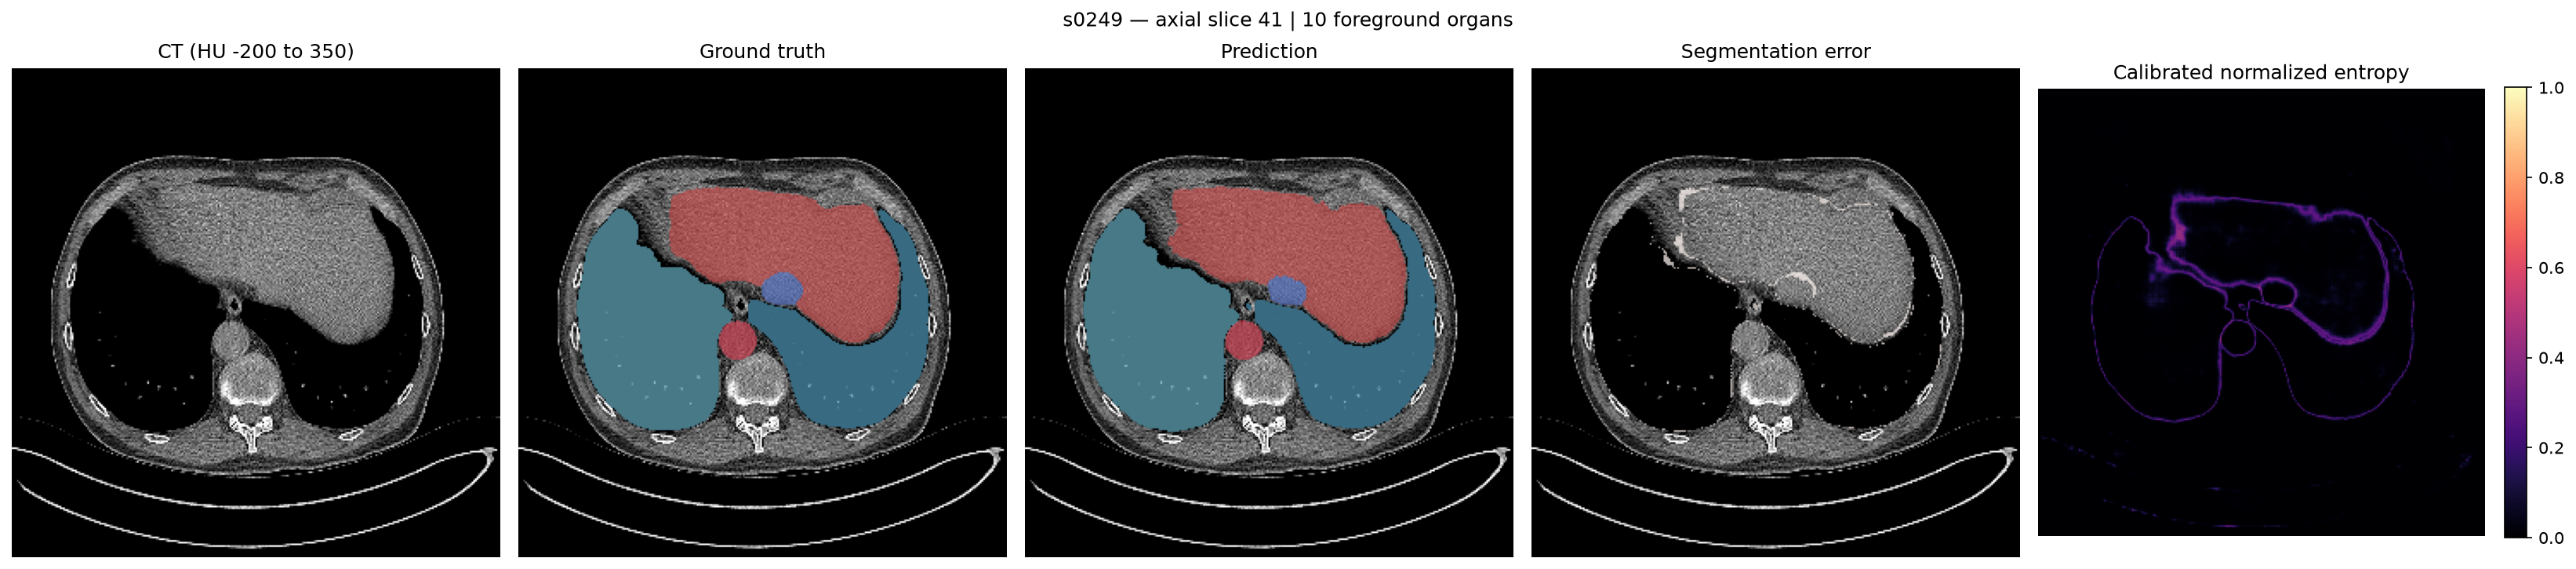

### Validation overlay — s1017

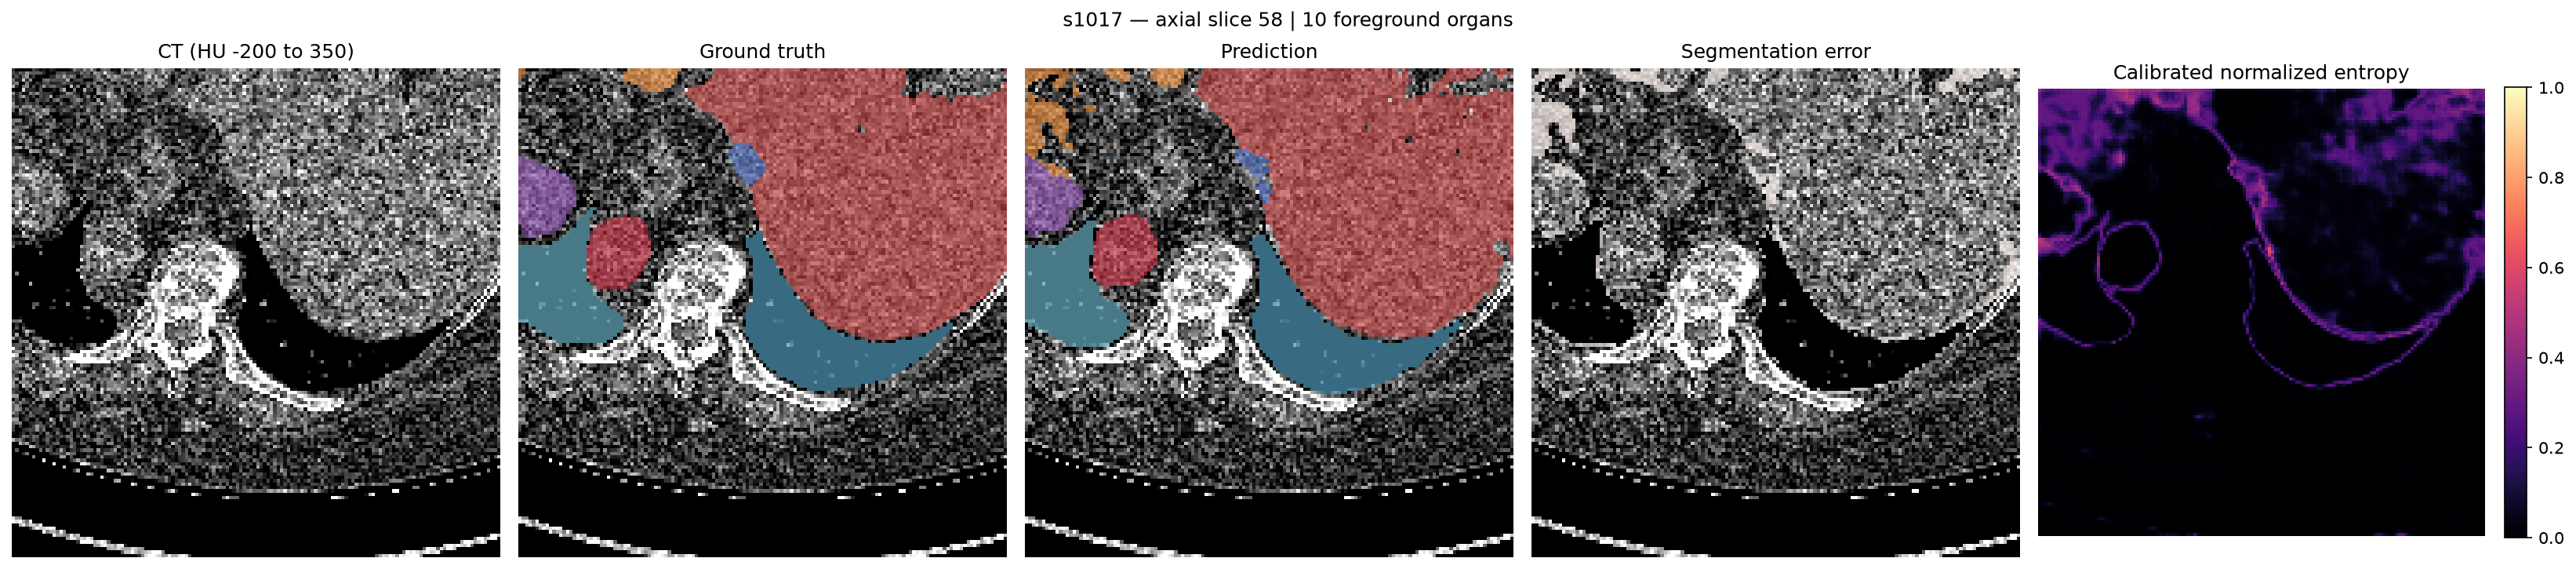

### Validation overlay — s1161

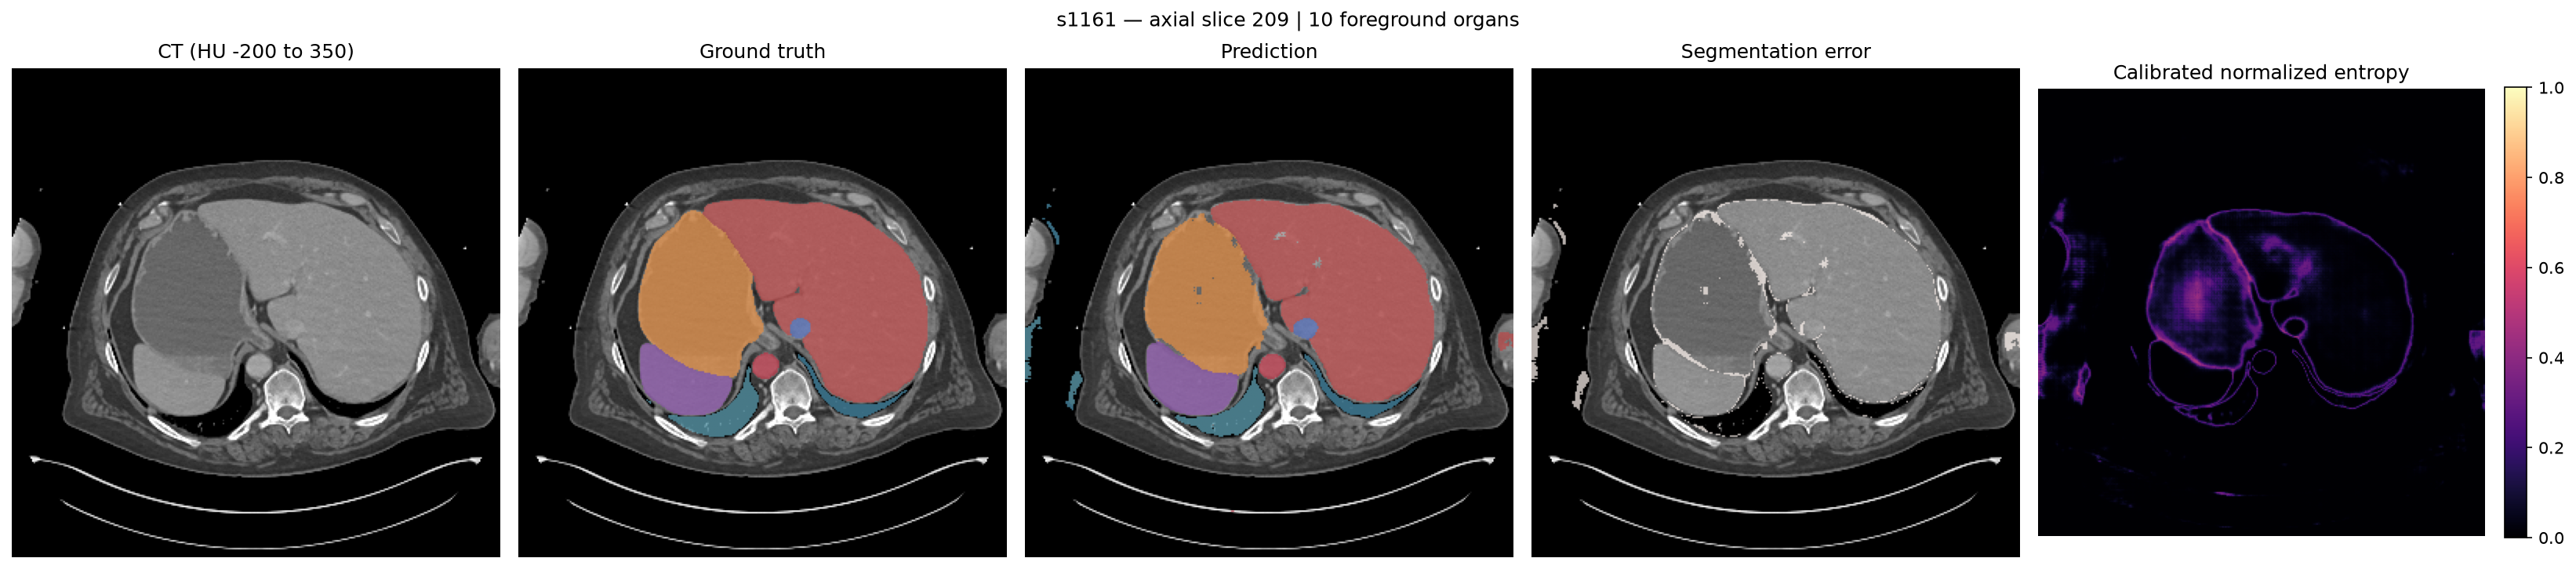

In [4]:
postprocessing_table = pd.DataFrame(
    [
        {
            "Policy": policy,
            "Validation macro Dice": summary["mean_foreground_dice"],
            "Selected": policy == validation_report["selected_postprocessing"],
        }
        for policy, summary in validation_report["postprocessing_candidates"].items()
    ]
).sort_values("Validation macro Dice", ascending=False)
display(postprocessing_table)

overlay_root = PROJECT_ROOT / phase6_config["outputs"]["validation"] / "qualitative_overlays"
for case_id in validation_report["qualitative_case_ids"]:
    display(Markdown(f"### Validation overlay — {case_id}"))
    display(Image(filename=str(overlay_root / f"{case_id}_overlay.png")))

## 3. Freeze every decision before opening test

This cell writes an immutable, hashed protocol containing the checkpoint hash, temperature, entropy threshold,
postprocessing policy, official test-ID hash, and the mesh-case selection rule. The mesh case is selected from
manifest CT geometry only—never from test labels or performance.

In [5]:
frozen_protocol = freeze_protocol(
    project_root=PROJECT_ROOT,
    phase6_config_path=PHASE6_CONFIG_PATH,
    phase6_config=phase6_config,
    baseline_config_path=BASELINE_CONFIG_PATH,
    manifest=manifest,
    schema=schema,
    context=context,
    validation_report=validation_report,
)
display(pd.DataFrame(
    [
        ("Protocol SHA-256", frozen_protocol["protocol_sha256"]),
        ("Temperature", frozen_protocol["temperature"]),
        ("Entropy error threshold", frozen_protocol["error_flag_threshold"]),
        ("Postprocessing", frozen_protocol["postprocessing_policy"]),
        ("Test cases", frozen_protocol["test_case_count"]),
        ("Predeclared mesh case", frozen_protocol["mesh_selection"]["case_id"]),
        ("Test labels used for selection", frozen_protocol["test_labels_used_for_any_selection"]),
    ],
    columns=["Frozen item", "Value"],
))
assert frozen_protocol["test_labels_used_for_any_selection"] is False

,Frozen item,Value
0,Protocol SHA-256,b0a5f3239922d99741569a25d3e202b7f7ac1287cb823c...
1,Temperature,1.035455
2,Entropy error threshold,0.231567
3,Postprocessing,none
4,Test cases,89
5,Predeclared mesh case,s0244
6,Test labels used for selection,False


## 4. One-shot official locked-test evaluation

This is the first cell authorized to open a test CT or test target. It uses only the frozen values above.
Results are committed per case. A restart may resume missing cases under the identical protocol hash, but a
completed test report is reused and cannot be retuned or silently replaced.

In [6]:
assert RUN_ONE_SHOT_LOCKED_TEST is True
test_receipt = authorize_one_shot_test(
    project_root=PROJECT_ROOT,
    phase6_config=phase6_config,
    protocol=frozen_protocol,
)
test_report = run_locked_test_evaluation(
    project_root=PROJECT_ROOT,
    dataset_root=DATASET_ROOT,
    phase6_config=phase6_config,
    baseline_config=baseline_config,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
    context=context,
    protocol=frozen_protocol,
    receipt=test_receipt,
)
assert test_report["status"] == "complete_one_shot"
assert test_report["cases"] == 89
assert test_report["no_test_time_tuning"] is True
print("Locked test evaluation complete. No value was tuned on test.")

Locked test evaluation already complete; verified and reused.
Locked test evaluation complete. No value was tuned on test.


In [7]:
dice_table = pd.DataFrame(test_report["segmentation"]["per_class"])[
    ["class_id", "organ", "dice_mean", "dice_std", "hd95_mm_mean", "valid_dice_cases"]
]
display(dice_table.style.format({"dice_mean": "{:.4f}", "dice_std": "{:.4f}", "hd95_mm_mean": "{:.2f}"}))
display(pd.DataFrame(
    [
        ("Test macro foreground Dice", test_report["segmentation"]["mean_foreground_dice"]),
        ("Patient-level Dice 95% CI lower", test_report["patient_level_macro_dice_ci95"]["ci95_lower"]),
        ("Patient-level Dice 95% CI upper", test_report["patient_level_macro_dice_ci95"]["ci95_upper"]),
        ("Uncertainty error AUROC", test_report["uncertainty_error_analysis"]["error_detection_auroc"]),
        ("Uncertainty error AUPRC", test_report["uncertainty_error_analysis"]["error_detection_auprc"]),
        ("Test ECE (frozen temperature)", test_report["calibration_at_frozen_temperature"]["ece_15_bin"]),
    ],
    columns=["Final test metric", "Value"],
))

,class_id,organ,dice_mean,dice_std,hd95_mm_mean,valid_dice_cases
0,1,liver,0.9274,0.1644,13.66,70
1,2,spleen,0.9453,0.0645,11.51,65
2,3,kidney_left,0.8451,0.2153,38.66,68
3,4,kidney_right,0.8693,0.2319,24.29,64
4,5,stomach,0.8462,0.1892,28.21,66
5,6,pancreas,0.7182,0.2450,8.76,65
6,7,aorta,0.8729,0.1832,75.36,77
7,8,inferior_vena_cava,0.7953,0.2001,26.49,72
8,9,lung_left,0.9597,0.0600,71.47,73
9,10,lung_right,0.9466,0.1182,87.02,73


,Final test metric,Value
0,Test macro foreground Dice,0.872591
1,Patient-level Dice 95% CI lower,0.807936
2,Patient-level Dice 95% CI upper,0.888138
3,Uncertainty error AUROC,0.979250
4,Uncertainty error AUPRC,0.344643
5,Test ECE (frozen temperature),0.000693


## 5. Full-resolution 3D anatomical reconstruction and digital twin

Marching cubes is applied to the postprocessed prediction of the predeclared test case. Vertices are transformed
by the resampled RAS affine into patient-space millimetres. Each organ is exported as PLY and STL; all organs are
combined into a portable GLB digital twin. PLY vertex colors blend toward yellow as calibrated entropy rises.
The HTML viewer is face-capped only for browser responsiveness; the files on disk remain full resolution.

Existing full mesh report verified and reused.


,class_id,organ,status,input_voxels,vertices,faces,watertight,surface_area_mm2,volume_ml_if_watertight,ply,stl
0,1,liver,exported,340145,51004,102028,True,84705.591695,1147.598016,individual_organs/liver.ply,individual_organs/liver.stl
1,2,spleen,exported,56076,14000,28004,True,23022.621842,189.010547,individual_organs/spleen.ply,individual_organs/spleen.stl
2,3,kidney_left,exported,41311,17703,35168,False,28177.781000,NaN,individual_organs/kidney_left.ply,individual_organs/kidney_left.stl
3,4,kidney_right,exported,39572,13624,27256,True,22136.819393,133.405313,individual_organs/kidney_right.ply,individual_organs/kidney_right.stl
4,5,stomach,exported,114373,33817,68006,False,54185.742968,NaN,individual_organs/stomach.ply,individual_organs/stomach.stl
5,6,pancreas,exported,21432,10997,21986,True,17842.127114,71.965266,individual_organs/pancreas.ply,individual_organs/pancreas.stl
6,7,aorta,exported,34140,13981,27856,False,22917.197169,NaN,individual_organs/aorta.ply,individual_organs/aorta.stl
7,8,inferior_vena_cava,exported,26461,10729,21356,False,18110.381837,NaN,individual_organs/inferior_vena_cava.ply,individual_organs/inferior_vena_cava.stl
8,9,lung_left,exported,100102,20010,39484,False,32772.106670,NaN,individual_organs/lung_left.ply,individual_organs/lung_left.stl
9,10,lung_right,exported,286564,36402,72262,False,60793.519152,NaN,individual_organs/lung_right.ply,individual_organs/lung_right.stl


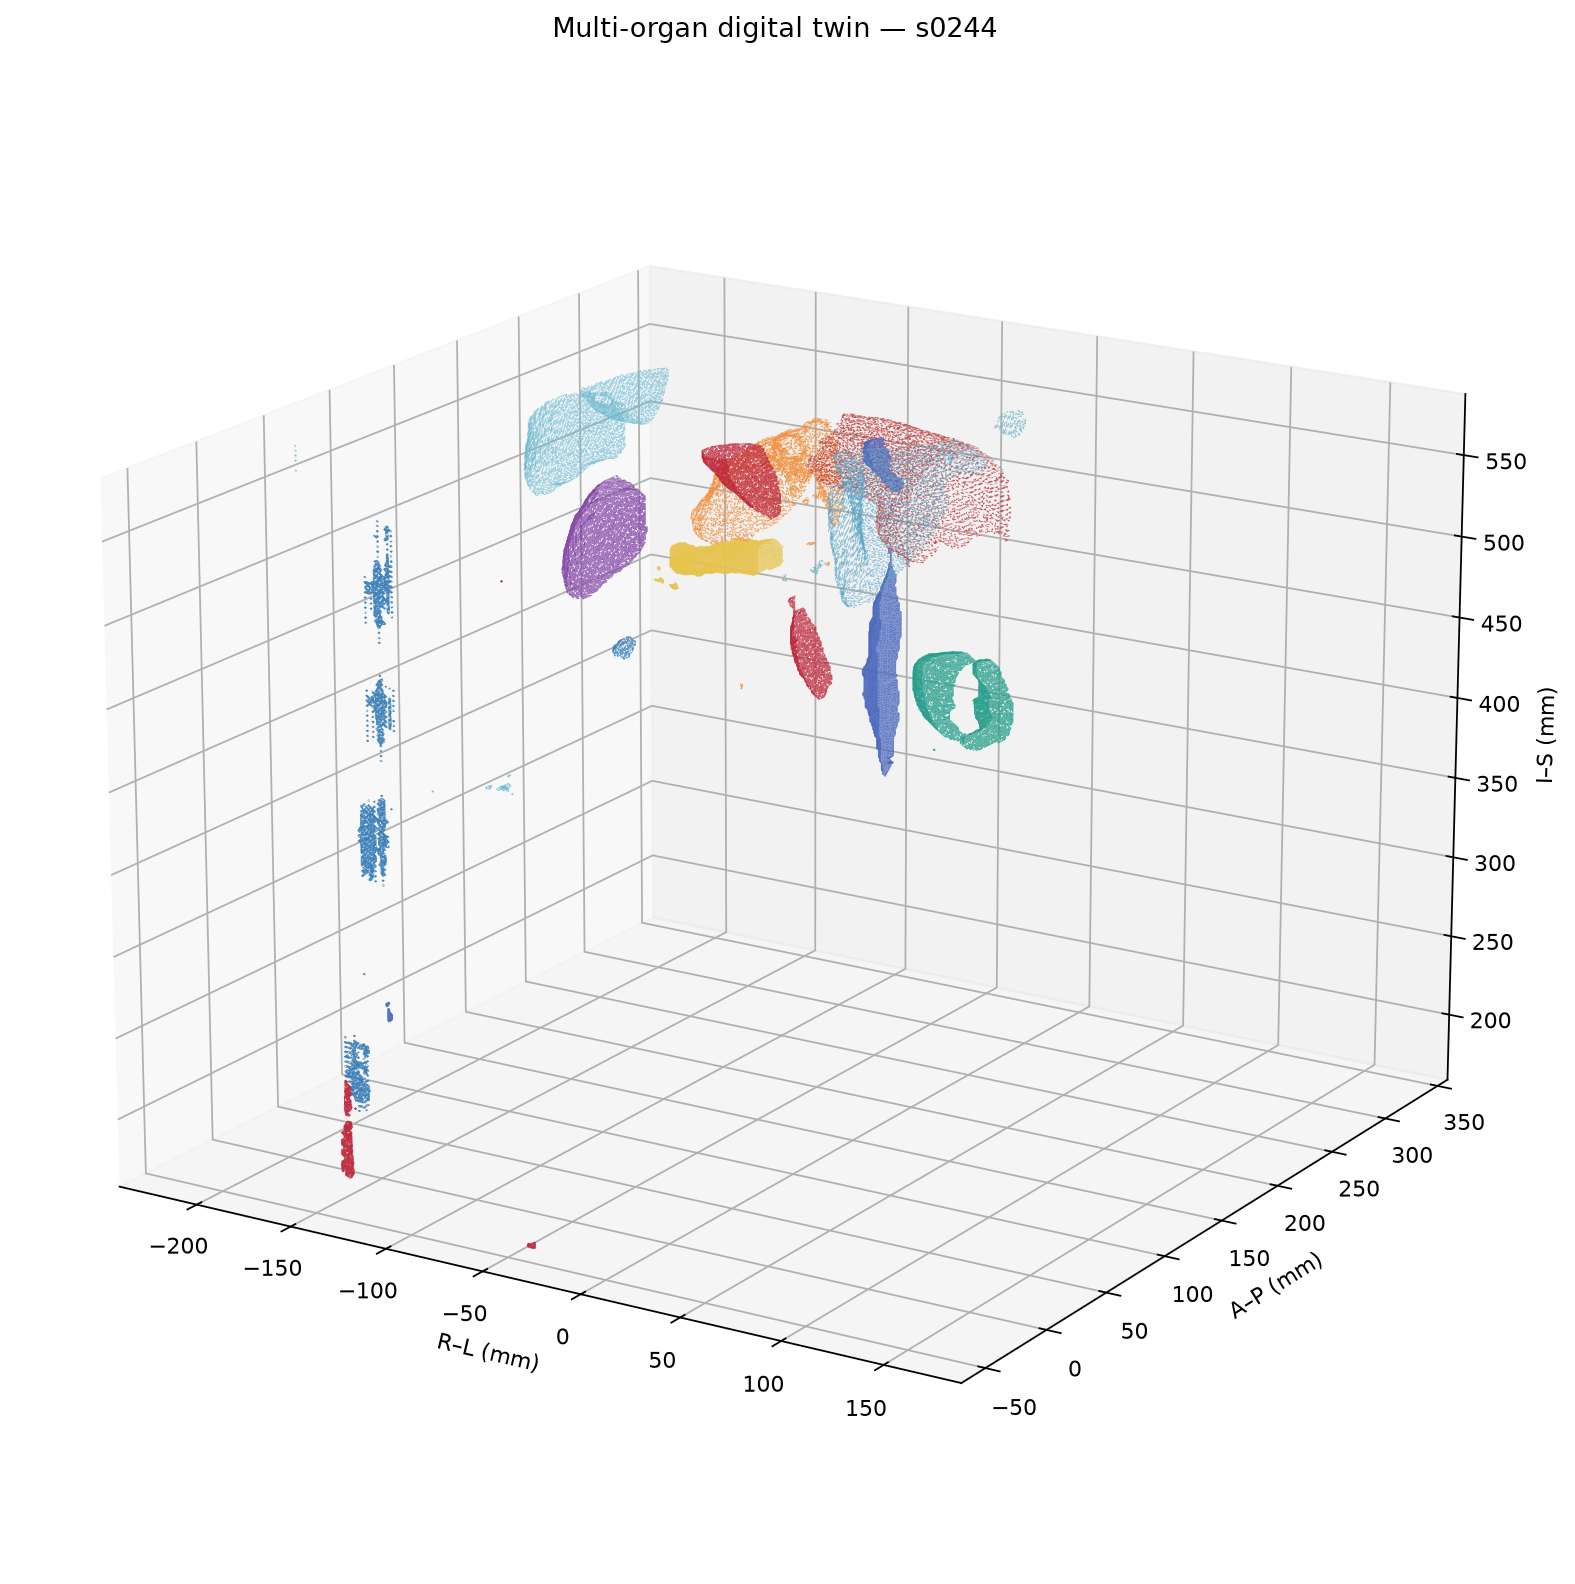

In [8]:
assert RUN_3D_MESH is True
mesh_volume_path = PROJECT_ROOT / phase6_config["outputs"]["test"] / "predeclared_mesh_case_volume.npz"
assert mesh_volume_path.is_file(), "Complete the one-shot test cell first"
mesh_output_root = PROJECT_ROOT / phase6_config["outputs"]["mesh"]
mesh_report_path = mesh_output_root / "mesh_report.json"
if mesh_report_path.is_file():
    mesh_report = json.loads(mesh_report_path.read_text(encoding="utf-8"))
    print("Existing full mesh report verified and reused.")
else:
    with np.load(mesh_volume_path) as volume:
        mesh_report = build_patient_meshes(
            prediction=volume["prediction"],
            uncertainty=volume["uncertainty"].astype(np.float32),
            affine=volume["affine"],
            class_names={label.id: label.name for label in schema.labels},
            output_root=mesh_output_root,
            case_id=str(volume["case_id"].item()),
            max_html_faces_per_organ=int(phase6_config["mesh"]["max_html_faces_per_organ"]),
        )
exported = pd.DataFrame(mesh_report["organs"])
display(exported)
display(Image(filename=str(mesh_output_root / mesh_report["preview_png"])))

In [9]:
interactive_path = mesh_output_root / mesh_report["interactive_html"]
glb_path = mesh_output_root / mesh_report["combined_glb"]
display(Markdown(
    f"### Final 3D mesh\n\n"
    f"- **Interactive digital twin:** `{interactive_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Portable combined GLB:** `{glb_path.relative_to(PROJECT_ROOT)}`\n"
    f"- **Individual full-resolution PLY/STL meshes:** `{(mesh_output_root / 'individual_organs').relative_to(PROJECT_ROOT)}`"
))
display(IFrame(src=interactive_path.as_uri(), width="100%", height=760))

### Final 3D mesh

- **Interactive digital twin:** `outputs\phase6\digital_twin\s0244_digital_twin.html`
- **Portable combined GLB:** `outputs\phase6\digital_twin\s0244_digital_twin.glb`
- **Individual full-resolution PLY/STL meshes:** `outputs\phase6\digital_twin\individual_organs`